# Applications V: Statistical and Thermal Physics

- [A5.1 Heat capacity of solids: Einstein vs Debye](#debye) - *quadrature, curve fitting (Ch. 4, 9)*
- [A5.2 The Fermi gas: finding the chemical potential](#fermi) - *root finding + quadrature (Ch. 3, 4)*
- [A5.3 The 2D Ising model of a magnet](#ising) - *Metropolis Monte Carlo (Ch. 10)*
- [A5.4 Phase transition: measuring the critical temperature](#critical) - *Monte Carlo, error analysis (Ch. 10)*
- [A5.5 From random walks to the diffusion equation](#diffusion) - *random walks, FTCS (Ch. 7, 10)*
- [Projects](#projects)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import brentq, curve_fit

# A5.1 Heat capacity of solids: Einstein vs Debye <a class="anchor" id="debye"></a>
Classically, every atom in a solid contributes $3k_B$ to the heat capacity (the Dulong-Petit law), but experiments show $C_V\to0$ as $T\to0$. Einstein (1907) treated each atom as a quantum oscillator of a single frequency; Debye (1912) used a spectrum of sound waves up to a cut-off frequency. Per mole:

$$C_\text{Einstein} = 3R\frac{x^2e^x}{(e^x-1)^2},\ \ x=\frac{\Theta_E}{T};\qquad
  C_\text{Debye} = 9R\left(\frac{T}{\Theta_D}\right)^3\int_0^{\Theta_D/T}\frac{x^4e^x}{(e^x-1)^2}dx.$$

The Debye integral has no closed form, so we evaluate it numerically and then **fit** $\Theta_D$ to (approximate) measured data for copper.

fitted Debye temperature   Theta_D = 312 ± 5 K  (tabulated low-T value: 343 K)
fitted Einstein temperature Theta_E = 228 K


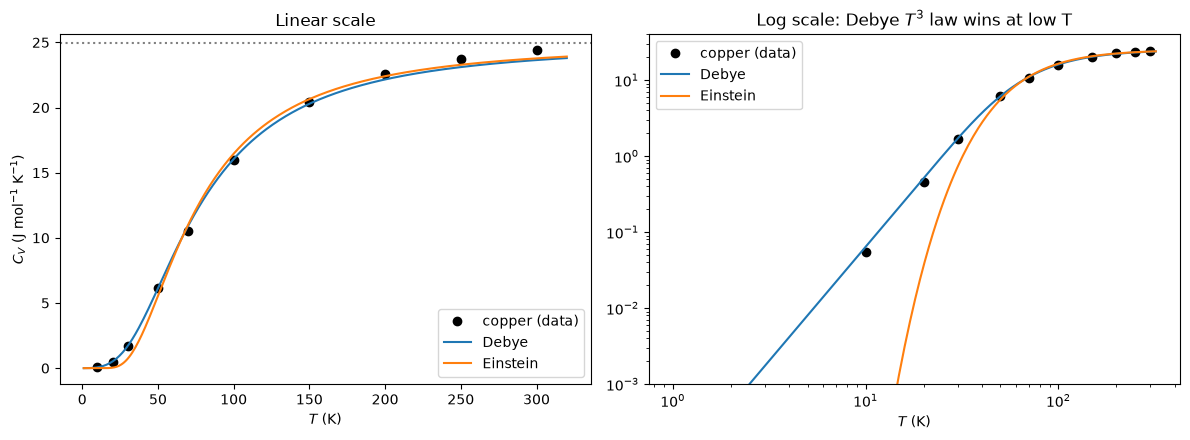

In [2]:
R = 8.314

def C_einstein(T, theta_E):
    x = theta_E/np.asarray(T, float)
    return 3*R*x**2*np.exp(x)/np.expm1(x)**2

def C_debye(T, theta_D):
    T = np.atleast_1d(np.asarray(T, float))
    integrand = lambda x: x**4*np.exp(x)/np.expm1(x)**2 if x > 0 else 0.0
    return np.array([9*R*(t/theta_D)**3*quad(integrand, 0, theta_D/t)[0] for t in T])

# Approximate molar heat capacity of copper (J/mol/K)
T_data = np.array([10, 20, 30, 50, 70, 100, 150, 200, 250, 300])
C_data = np.array([0.055, 0.46, 1.69, 6.15, 10.5, 16.0, 20.4, 22.6, 23.7, 24.4])

(theta_D,), cov = curve_fit(C_debye, T_data, C_data, p0=[300])
(theta_E,), _ = curve_fit(C_einstein, T_data, C_data, p0=[250])
print(f'fitted Debye temperature   Theta_D = {theta_D:.0f} ± {np.sqrt(cov[0, 0]):.0f} K  (tabulated low-T value: 343 K)')
print(f'fitted Einstein temperature Theta_E = {theta_E:.0f} K')

T = np.linspace(1, 320, 300)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
for ax in (ax1, ax2):
    ax.plot(T_data, C_data, 'ko', label='copper (data)')
    ax.plot(T, C_debye(T, theta_D), label='Debye')
    ax.plot(T, C_einstein(T, theta_E), label='Einstein')
    ax.set_xlabel('$T$ (K)'); ax.legend()
ax1.axhline(3*R, ls=':', color='grey'); ax1.set_ylabel('$C_V$ (J mol$^{-1}$ K$^{-1}$)'); ax1.set_title('Linear scale')
ax2.set_xscale('log'); ax2.set_yscale('log'); ax2.set_ylim(1e-3, 40); ax2.set_title('Log scale: Debye $T^3$ law wins at low T')
plt.tight_layout(); plt.show()

The Debye model captures the $T^3$ law at low temperature that Einstein's model misses completely (Einstein's $C_V$ falls off exponentially). Our fitted $\Theta_D$ is a little below the tabulated 343 K: that value is defined from the low-temperature $T^3$ region, while our fit is dominated by the high-temperature points, where copper's real phonon spectrum differs from Debye's idealised one. Try fitting only the points below 30 K!

# A5.2 The Fermi gas: finding the chemical potential <a class="anchor" id="fermi"></a>
Electrons in a metal fill states up to the Fermi energy $E_F$. At temperature $T$ the occupation is $f(E) = 1/(e^{(E-\mu)/k_BT}+1)$, and the chemical potential $\mu(T)$ is fixed by requiring the number of electrons to stay constant:

$$N = \int_0^\infty g(E)f(E)\,dE, \qquad g(E)\propto\sqrt E.$$

In units of $E_F$, the condition is $\displaystyle\frac{3}{2}\int_0^\infty\frac{\sqrt{\epsilon}\,d\epsilon}{e^{(\epsilon-\tilde\mu)/\tilde T}+1} = 1$. For each $\tilde T$ this is an equation for $\tilde\mu$ whose left-hand side is itself an integral: we nest **quadrature inside root-finding**. The Sommerfeld expansion predicts $\tilde\mu\approx1-\frac{\pi^2}{12}\tilde T^2$ at low $T$; at high $T$ the gas becomes classical and $\mu$ becomes large and negative.

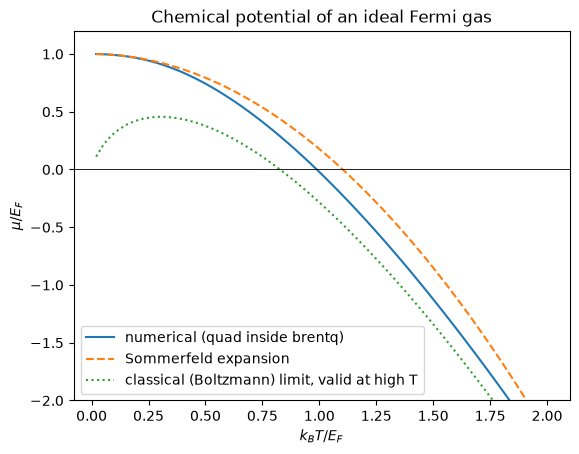

mu = 0 at T = 0.9887 E_F/k_B


In [3]:
def number_integral(mu, T):
    integrand = lambda e: 1.5*np.sqrt(e)/(np.exp(np.clip((e - mu)/T, -700, 700)) + 1)
    upper = max(mu, 0) + 50*T                       # the integrand is negligible beyond this
    return quad(integrand, 0, upper, points=[max(mu, 0)], limit=200)[0]

def chemical_potential(T):
    return brentq(lambda mu: number_integral(mu, T) - 1, -50, 2)

Ts = np.linspace(0.02, 2, 60)
mus = np.array([chemical_potential(T) for T in Ts])
plt.plot(Ts, mus, label='numerical (quad inside brentq)')
plt.plot(Ts, 1 - np.pi**2/12*Ts**2, '--', label='Sommerfeld expansion')
plt.plot(Ts, Ts*np.log(4/(3*np.sqrt(np.pi))*Ts**-1.5), ':', label='classical (Boltzmann) limit, valid at high T')
plt.axhline(0, color='k', lw=0.6); plt.ylim(-2, 1.2)
plt.xlabel('$k_BT/E_F$'); plt.ylabel(r'$\mu/E_F$'); plt.legend(); plt.title('Chemical potential of an ideal Fermi gas')
plt.show()
print(f'mu = 0 at T = {brentq(lambda T: chemical_potential(T), 0.3, 1.5):.4f} E_F/k_B')

For copper, $E_F\approx7$ eV corresponds to $T_F\approx80\,000$ K, so at room temperature $\tilde T\approx0.004$ and $\mu\approx E_F$ to one part in $10^5$ - which is why the free-electron heat capacity is so small.

# A5.3 The 2D Ising model of a magnet <a class="anchor" id="ising"></a>
The simplest model of a ferromagnet: spins $s_i=\pm1$ on a square lattice, each interacting with its four nearest neighbours,

$$E = -J\sum_{\langle ij\rangle}s_is_j.$$

Aligned neighbours lower the energy, but thermal fluctuations favour disorder. In 1944 Onsager solved the 2D model exactly and found a **phase transition** at $k_BT_c/J = 2/\ln(1+\sqrt2)\approx2.269$: below it, the magnet spontaneously magnetises,

$$|m| = \left[1 - \sinh^{-4}(2J/k_BT)\right]^{1/8}.$$

There are $2^{N}$ configurations - for a $64\times64$ lattice that's $10^{1233}$ - so we can't sum over them; instead we sample them with the **Metropolis algorithm** (Chapter 10.7). Flipping spin $i$ changes the energy by $\Delta E = 2Js_i\sum_\text{nbrs}s_j$, which only depends on its four neighbours.

**Vectorising with a checkerboard.** A Python loop over every spin is slow. On a chessboard, all the "black" spins' neighbours are "white", so we can attempt to flip **every black spin at once**, then every white spin, with numpy - typically 100$\times$ faster. Periodic boundary conditions are done with `np.roll`.

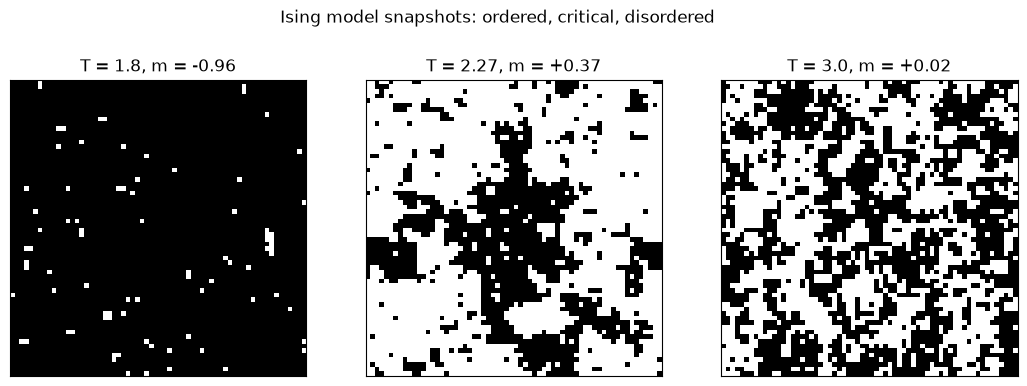

In [4]:
rng = np.random.default_rng(2024)

def neighbour_sum(s):
    return np.roll(s, 1, 0) + np.roll(s, -1, 0) + np.roll(s, 1, 1) + np.roll(s, -1, 1)

def sweep(s, beta, masks):
    """One Monte Carlo sweep (J = k_B = 1): a Metropolis update of every spin."""
    for mask in masks:
        dE = 2*s*neighbour_sum(s)
        flip = mask & (rng.random(s.shape) < np.exp(-beta*dE))
        s[flip] *= -1
    return s

L = 64
I, Jj = np.indices((L, L))
masks = [(I + Jj) % 2 == 0, (I + Jj) % 2 == 1]

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, T in zip(axes, [1.8, 2.27, 3.0]):
    s = rng.choice([-1, 1], size=(L, L))
    for _ in range(600):
        sweep(s, 1/T, masks)
    ax.imshow(s, cmap='gray'); ax.set_title(f'T = {T}, m = {s.mean():+.2f}')
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle('Ising model snapshots: ordered, critical, disordered'); plt.show()

Below $T_c$ large domains form (they may still be coarsening after a finite number of sweeps); at $T_c$ there are clusters of every size - the hallmark of a critical point; above $T_c$ the spins are disordered.

# A5.4 Phase transition: measuring the critical temperature <a class="anchor" id="critical"></a>
For each temperature we equilibrate, then measure the average magnetisation per spin $\langle|m|\rangle$, energy per spin $\langle e\rangle$, and from the *fluctuations* (the fluctuation-dissipation theorem):

$$c = \frac{N(\langle e^2\rangle - \langle e\rangle^2)}{T^2},\qquad \chi = \frac{N(\langle m^2\rangle - \langle |m|\rangle^2)}{T}.$$

We start from the ordered state at low $T$ and *heat* the system gradually, reusing each final configuration as the next starting point (an *annealing schedule* that saves equilibration time).

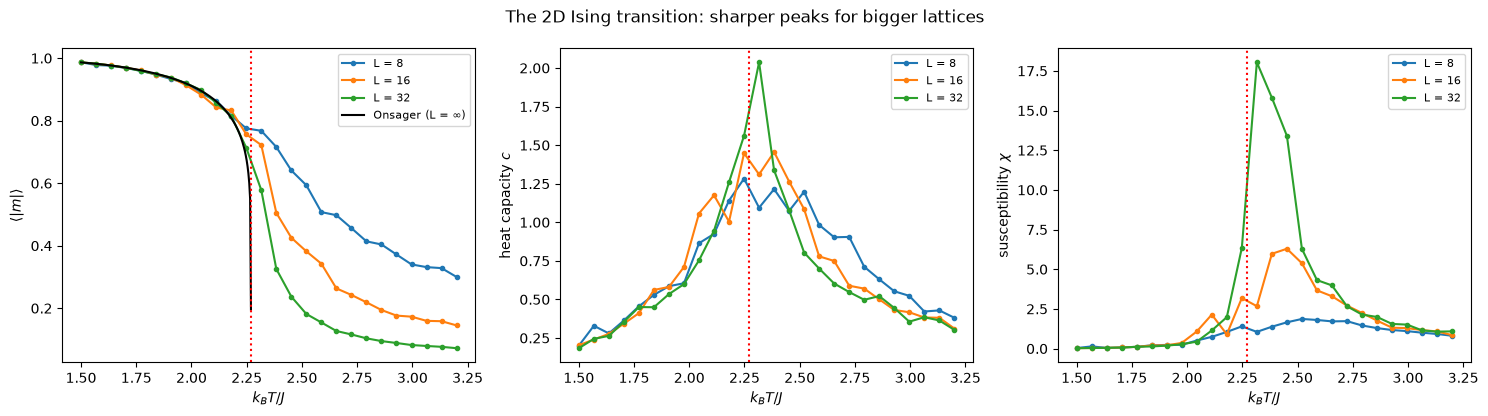

L =  8: susceptibility peaks at T = 2.520   (Onsager T_c = 2.269)
L = 16: susceptibility peaks at T = 2.452   (Onsager T_c = 2.269)
L = 32: susceptibility peaks at T = 2.316   (Onsager T_c = 2.269)


In [5]:
def measure(L, temps, n_equil=400, n_meas=1200, every=2):
    I, J_ = np.indices((L, L))
    masks = [(I + J_) % 2 == 0, (I + J_) % 2 == 1]
    N = L*L
    s = np.ones((L, L), dtype=int)
    results = []
    for T in temps:
        beta = 1/T
        for _ in range(n_equil):
            sweep(s, beta, masks)
        ms, es = [], []
        for k in range(n_meas):
            sweep(s, beta, masks)
            if k % every == 0:
                ms.append(abs(s.mean()))
                es.append(-np.sum(s*np.roll(s, 1, 0) + s*np.roll(s, 1, 1))/N)
        ms, es = np.array(ms), np.array(es)
        results.append([ms.mean(), es.mean(), N*es.var()/T**2, N*ms.var()/T])
    return np.array(results)

temps = np.linspace(1.5, 3.2, 26)
res = {L: measure(L, temps) for L in [8, 16, 32]}

Tc = 2/np.log(1 + np.sqrt(2))
T_fine = np.linspace(1.5, Tc - 1e-6, 200)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for L, r in res.items():
    axes[0].plot(temps, r[:, 0], 'o-', ms=3, label=f'L = {L}')
    axes[1].plot(temps, r[:, 2], 'o-', ms=3, label=f'L = {L}')
    axes[2].plot(temps, r[:, 3], 'o-', ms=3, label=f'L = {L}')
axes[0].plot(T_fine, (1 - np.sinh(2/T_fine)**-4)**(1/8), 'k', label='Onsager (L = ∞)')
for ax, lab in zip(axes, [r'$\langle|m|\rangle$', 'heat capacity $c$', r'susceptibility $\chi$']):
    ax.axvline(Tc, color='r', ls=':'); ax.set_xlabel('$k_BT/J$'); ax.set_ylabel(lab); ax.legend(fontsize=8)
plt.suptitle('The 2D Ising transition: sharper peaks for bigger lattices'); plt.tight_layout(); plt.show()

for L, r in res.items():
    print(f'L = {L:>2}: susceptibility peaks at T = {temps[np.argmax(r[:, 3])]:.3f}   (Onsager T_c = {Tc:.3f})')

A finite system can't have a true singularity, so the peaks are rounded and shifted - but they sharpen and move towards $T_c$ as $L$ grows. **Finite-size scaling** theory says the peak position behaves as $T_c(L) = T_c + aL^{-1/\nu}$ with $\nu=1$ in 2D; extrapolating to $L\to\infty$ is how critical temperatures of unsolved models (like the 3D Ising model) are measured.

# A5.5 From random walks to the diffusion equation <a class="anchor" id="diffusion"></a>
Release 20 000 particles at the origin, let each take random $\pm1$ steps, and compare their spread with the diffusion equation $\partial_t n = D\partial_x^2n$ solved by FTCS (Chapter 7). For unit steps per unit time, $D=\frac12$, and the exact solution is a spreading Gaussian with variance $2Dt$.

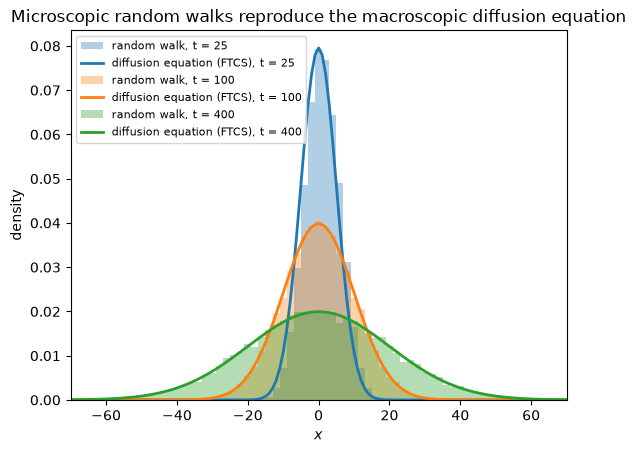

t =  25: variance of walkers =    24.9,  2Dt = 25
t = 100: variance of walkers =    99.9,  2Dt = 100
t = 400: variance of walkers =   399.8,  2Dt = 400


In [6]:
n_particles, t_max = 20000, 400
pos = np.zeros(n_particles, dtype=int)
snapshots = {}
for t in range(1, t_max + 1):
    pos += rng.choice([-1, 1], size=n_particles)
    if t in (25, 100, 400):
        snapshots[t] = pos.copy()

# FTCS solution of the diffusion equation on the same grid
D, dx = 0.5, 1.0
x = np.arange(-100, 101)*dx
n = np.zeros_like(x, dtype=float); n[100] = 1/dx
dt = 0.4*dx**2/D
profiles = {}
t = 0.0
while t < t_max - 1e-9:
    n[1:-1] = n[1:-1] + D*dt/dx**2*(n[2:] - 2*n[1:-1] + n[:-2])
    t += dt
    for ts in (25, 100, 400):
        if abs(t - ts) < dt/2:
            profiles[ts] = n.copy()

for ts, c in zip((25, 100, 400), ['C0', 'C1', 'C2']):
    # random-walk positions after t steps all have the parity of t, so use bins 2 wide
    plt.hist(snapshots[ts], bins=np.arange(-101, 102, 2), density=True, alpha=0.35, color=c, label=f'random walk, t = {ts}')
    plt.plot(x, profiles[ts], color=c, lw=2, label=f'diffusion equation (FTCS), t = {ts}')
plt.xlim(-70, 70); plt.xlabel('$x$'); plt.ylabel('density'); plt.legend(fontsize=8)
plt.title('Microscopic random walks reproduce the macroscopic diffusion equation'); plt.show()
for ts in (25, 100, 400):
    print(f't = {ts:>3}: variance of walkers = {snapshots[ts].var():7.1f},  2Dt = {2*D*ts:.0f}')

# Projects <a class="anchor" id="projects"></a>

1. **Hysteresis.** Add an external field term $-h\sum_is_i$ to the Ising energy. At $T=1.5$, sweep $h$ slowly from $-1$ to $+1$ and back, recording $m$. Plot the hysteresis loop. How does it change with temperature?
2. **Critical exponents.** Using lattices of size $L=8$ to $64$, measure the peak height of $\chi$ and show that $\chi_\text{max}\propto L^{\gamma/\nu}$ with $\gamma/\nu = 7/4$.
3. **Bose-Einstein condensation.** Repeat A5.2 for bosons, $f(E) = 1/(e^{(E-\mu)/k_BT}-1)$ with $\mu\le0$. Show that below a critical temperature no $\mu\le0$ can satisfy the number equation - the "missing" particles are in the ground state. Plot the condensate fraction against $T/T_c$ and compare with $1-(T/T_c)^{3/2}$.
4. **A lattice gas.** Reinterpret Ising spins as occupied/empty sites to model a liquid-gas transition. Use *Kawasaki dynamics* (swap neighbouring opposite spins instead of flipping) to conserve particle number and watch a gas condense into droplets.
5. **Entropy of mixing.** Simulate two gases initially separated in a box (random walkers with a removable wall) and compute the Gibbs entropy from histograms of particle positions as a function of time.

In [7]:
# Start working here